In [1]:
# ==============================================================================
#PROJECT : SPATIOTEMPORAL CBAM ATTENTION & FOCAL-LOSS NEURAL DECODER
# Benchmarked Against Minimum-Weight Perfect Matching (PyMatching MWPM) & MLP
# Multi-Seed Evaluation (3 Seeds) on Exact Rotated d=3 Surface Code (Non-Pauli Noise)
# Author: Surat Sai Venkata Nagendra Babu
# ==============================================================================

!pip install -q pymatching

import gc
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pymatching
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, roc_curve, f1_score, recall_score
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model

print("GPUs Available:", tf.config.list_physical_devices('GPU'))

# ==============================================================================
# 1. EXACT ROTATED d=3 SURFACE CODE STABILIZERS & NON-PAULI NOISE SIMULATOR
# ==============================================================================
# 3x3 Data Qubit Grid:
#   0 -- 1 -- 2
#   |    |    |
#   3 -- 4 -- 5
#   |    |    |
#   6 -- 7 -- 8

# Z-stabilizers detect X-errors (every qubit has column weight <= 2 for MWPM)
Z_STABILIZERS = [[0, 1, 3, 4], [4, 5, 7, 8], [1, 2], [6, 7]]
# X-stabilizers detect Z-errors (every qubit has column weight <= 2 for MWPM)
X_STABILIZERS = [[1, 2, 4, 5], [3, 4, 6, 7], [0, 3], [5, 8]]

# Logical Z operator [0, 3, 6] detects Logical X flips; Logical X [0, 1, 2] detects Logical Z flips
LOGICAL_Z_SUPPORT = [0, 3, 6]
LOGICAL_X_SUPPORT = [0, 1, 2]

# Build exact parity-check matrices H_Z and H_X for PyMatching (MWPM)
H_Z = np.zeros((4, 9), dtype=np.uint8)
for i, stab in enumerate(Z_STABILIZERS):
    H_Z[i, stab] = 1

H_X = np.zeros((4, 9), dtype=np.uint8)
for i, stab in enumerate(X_STABILIZERS):
    H_X[i, stab] = 1

# Standard Pauli-noise MWPM matchers (unaware of coherent ZZ crosstalk & X/Z correlations)
mwpm_x_decoder = pymatching.Matching.from_check_matrix(H_Z)
mwpm_z_decoder = pymatching.Matching.from_check_matrix(H_X)

def generate_rotated_d3_non_pauli_dataset(n_shots=40000, n_cycles=6, seed=42):
    """
    Simplified phenomenological simulation of a rotated d=3 surface code inspired by
    non-Pauli master-equation noise features:
      1. Biased T1/T2 relaxation + correlated Y-channel events
      2. Coherent spatial ZZ crosstalk between adjacent qubits
      3. Asymmetric SPAM readout errors across 6 measurement cycles
    Returns:
      X_grid: (n_shots, n_cycles, 3, 3, 1) spatiotemporal detection events
      final_syndromes: (n_shots, 8) final-cycle noisy syndromes for static MWPM
      y_logical: (n_shots,) exact logical observable class [0: I, 1: X, 2: Z, 3: Y]
    """
    rng = np.random.default_rng(seed)
    crosstalk_pairs = [(0, 1), (1, 2), (3, 4), (4, 5), (6, 7), (7, 8), (0, 3), (4, 7)]

    X_syndromes = np.zeros((n_shots, n_cycles, 9), dtype=np.float32)
    final_syndromes = np.zeros((n_shots, 8), dtype=np.uint8)
    y_logical = np.zeros(n_shots, dtype=np.int32)

    p_t1_x = 0.0080       # Biased T1 bit-flip rate per cycle
    p_t2_z = 0.0060       # T2 phase-flip rate per cycle
    p_corr_zz = 0.0055    # Coherent ZZ crosstalk on coupled pairs (confuses standard MWPM)
    p_corr_y = 0.0025     # Correlated X+Z (Y) event (MWPM decodes X & Z independently)
    p_meas = 0.0150       # Asymmetric readout error (1 -> 0 biased)

    for shot in range(n_shots):
        x_err = np.zeros(9, dtype=np.uint8)
        z_err = np.zeros(9, dtype=np.uint8)
        prev_syn = np.zeros(8, dtype=np.uint8)

        for t in range(n_cycles):
            new_x = (rng.random(9) < p_t1_x).astype(np.uint8)
            new_z = (rng.random(9) < p_t2_z).astype(np.uint8)

            # Correlated Y errors (simultaneous X and Z on same qubit)
            y_events = (rng.random(9) < p_corr_y).astype(np.uint8)
            new_x ^= y_events
            new_z ^= y_events

            # Spatial coherent ZZ crosstalk between neighboring qubits
            for q1, q2 in crosstalk_pairs:
                if rng.random() < p_corr_zz:
                    new_z[q1] ^= 1
                    new_z[q2] ^= 1
                    if rng.random() < 0.40:
                        new_x[q1] ^= 1

            x_err ^= new_x
            z_err ^= new_z

            # Compute exact stabilizer parity checks
            curr_syn = np.zeros(8, dtype=np.uint8)
            curr_syn[:4] = (H_X @ z_err) % 2   # First 4: X-stabilizers (detect Z)
            curr_syn[4:] = (H_Z @ x_err) % 2   # Last 4:  Z-stabilizers (detect X)

            # Asymmetric readout noise on cycles 0..n_cycles-2 (final cycle uses perfect readout or noisy)
            noisy_syn = curr_syn.copy()
            if t < n_cycles - 1:
                for s_idx in range(8):
                    if noisy_syn[s_idx] == 1 and rng.random() < (p_meas * 1.6):
                        noisy_syn[s_idx] = 0
                    elif noisy_syn[s_idx] == 0 and rng.random() < (p_meas * 0.6):
                        noisy_syn[s_idx] = 1

            det_event = noisy_syn ^ prev_syn
            prev_syn = noisy_syn

            X_syndromes[shot, t, :8] = det_event
            X_syndromes[shot, t, 8] = np.sum(det_event) % 2

        final_syndromes[shot] = prev_syn

        # Exact logical observable flip (commutation with L_Z and L_X)
        log_x = np.sum(x_err[LOGICAL_Z_SUPPORT]) % 2
        log_z = np.sum(z_err[LOGICAL_X_SUPPORT]) % 2

        if log_x == 0 and log_z == 0:
            y_logical[shot] = 0  # Logical I
        elif log_x == 1 and log_z == 0:
            y_logical[shot] = 1  # Logical X
        elif log_x == 0 and log_z == 1:
            y_logical[shot] = 2  # Logical Z
        else:
            y_logical[shot] = 3  # Logical Y

    return X_syndromes.reshape((n_shots, n_cycles, 3, 3, 1)), final_syndromes, y_logical

def evaluate_mwpm(final_syndromes, y_true):
    """Decodes test shots using PyMatching (standard independent-Pauli MWPM)."""
    n = len(y_true)
    preds = np.zeros(n, dtype=np.int32)
    for i in range(n):
        x_syn = final_syndromes[i, :4]  # X-stabilizers -> Z errors
        z_syn = final_syndromes[i, 4:]  # Z-stabilizers -> X errors
        corr_x = mwpm_x_decoder.decode(z_syn)
        corr_z = mwpm_z_decoder.decode(x_syn)
        pred_log_x = np.sum(corr_x[LOGICAL_Z_SUPPORT]) % 2
        pred_log_z = np.sum(corr_z[LOGICAL_X_SUPPORT]) % 2
        if pred_log_x == 0 and pred_log_z == 0:
            preds[i] = 0
        elif pred_log_x == 1 and pred_log_z == 0:
            preds[i] = 1
        elif pred_log_x == 0 and pred_log_z == 1:
            preds[i] = 2
        else:
            preds[i] = 3
    return preds

GPUs Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [3]:
# ==============================================================================
# 2. CUSTOM LAYERS & DAMPED CATEGORICAL FOCAL LOSS (From Your Springer Paper)
# ==============================================================================
class CategoricalFocalLoss(keras.losses.Loss):
    def __init__(self, alpha, gamma=1.5, label_smoothing=0.02, **kwargs):
        super().__init__(**kwargs)
        self.alpha = tf.constant(alpha, dtype=tf.float32)
        self.gamma = gamma
        self.label_smoothing = label_smoothing

    def call(self, y_true, y_pred):
        num_classes = tf.cast(tf.shape(y_true)[-1], tf.float32)
        y_true_smooth = y_true * (1.0 - self.label_smoothing) + (self.label_smoothing / num_classes)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        ce = -y_true_smooth * tf.math.log(y_pred)
        mod = tf.pow(1.0 - y_pred, self.gamma)
        return tf.reduce_sum(self.alpha * mod * ce, axis=-1)

class ChannelAttention(layers.Layer):
    def __init__(self, ratio=4, **kwargs):
        super().__init__(**kwargs)
        self.ratio = ratio

    def build(self, input_shape):
        channels = input_shape[-1]
        self.dense1 = layers.Dense(max(channels // self.ratio, 4), activation='relu')
        self.dense2 = layers.Dense(channels, activation='sigmoid')
        super().build(input_shape)

    def call(self, inputs):
        avg_pool = tf.reduce_mean(inputs, axis=[1, 2], keepdims=True)
        max_pool = tf.reduce_max(inputs, axis=[1, 2], keepdims=True)
        att = self.dense2(self.dense1(avg_pool)) + self.dense2(self.dense1(max_pool))
        return inputs * att

    def compute_output_shape(self, input_shape):
        return input_shape

class SpatialAttention(layers.Layer):
    def __init__(self, kernel_size=3, **kwargs):
        super().__init__(**kwargs)
        self.kernel_size = kernel_size

    def build(self, input_shape):
        self.conv = layers.Conv2D(1, self.kernel_size, padding='same', activation='sigmoid')
        super().build(input_shape)

    def call(self, inputs):
        avg_pool = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        max_pool = tf.reduce_max(inputs, axis=-1, keepdims=True)
        concat = tf.concat([avg_pool, max_pool], axis=-1)
        return inputs * self.conv(concat)

    def compute_output_shape(self, input_shape):
        return input_shape

def build_proposed_decoder(input_shape=(6, 3, 3, 1), num_classes=4):
    inputs = layers.Input(shape=input_shape)
    b1 = layers.TimeDistributed(layers.Conv2D(48, 3, padding='same', activation='relu'))(inputs)
    b1 = layers.TimeDistributed(layers.BatchNormalization())(b1)
    b1 = layers.TimeDistributed(ChannelAttention(ratio=4))(b1)
    b1 = layers.TimeDistributed(SpatialAttention(kernel_size=3))(b1)
    b1 = layers.TimeDistributed(layers.GlobalAveragePooling2D())(b1)

    b2 = layers.TimeDistributed(layers.Conv2D(48, 2, padding='same', activation='relu'))(inputs)
    b2 = layers.TimeDistributed(layers.BatchNormalization())(b2)
    b2 = layers.TimeDistributed(layers.Flatten())(b2)
    b2 = layers.TimeDistributed(layers.Dense(48, activation='relu'))(b2)

    fused = layers.Concatenate()([b1, b2])
    fused = layers.Dropout(0.25)(fused)

    x = layers.Bidirectional(layers.LSTM(96, return_sequences=False))(fused)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    return Model(inputs, outputs, name="Focal_CBAM_BiLSTM_Decoder")

def build_mlp_baseline(input_shape=(6, 3, 3, 1), num_classes=4):
    inp = layers.Input(shape=input_shape)
    x = layers.Flatten()(inp)
    x = layers.Dense(96, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(48, activation='relu')(x)
    out = layers.Dense(num_classes, activation='softmax')(x)
    return Model(inp, out, name="Baseline_MLP_CE")

In [4]:
# ==============================================================================
# 3. MULTI-SEED EVALUATION (3 SEEDS): MWPM vs. CE-MLP vs. PROPOSED DECODER
# ==============================================================================
SEEDS = [42, 100, 2026]
class_names = ["Logical_I (Safe)", "Logical_X (BitFlip)", "Logical_Z (PhaseFlip)", "Logical_Y (Combined)"]

results = {
    "MWPM": {"ler": [], "macro_f1": [], "y_recall": []},
    "MLP_CE": {"ler": [], "macro_f1": [], "y_recall": [], "micro_auc": []},
    "Proposed": {"ler": [], "macro_f1": [], "y_recall": [], "micro_auc": []}
}

last_cm_data = None

for seed in SEEDS:
    print(f"\n{'='*70}\nRUNNING SEED {seed}\n{'='*70}")
    np.random.seed(seed)
    tf.random.set_seed(seed)
    tf.keras.backend.clear_session()
    gc.collect()

    X_all, syn_final, y_all = generate_rotated_d3_non_pauli_dataset(n_shots=40000, n_cycles=6, seed=seed)
    idx_all = np.arange(len(y_all))
    idx_tr, idx_tmp, y_tr, y_tmp = train_test_split(idx_all, y_all, test_size=0.30, random_state=seed, stratify=y_all)
    idx_val, idx_te, y_val, y_te = train_test_split(idx_tmp, y_tmp, test_size=0.50, random_state=seed, stratify=y_tmp)

    X_tr, X_val, X_te = X_all[idx_tr], X_all[idx_val], X_all[idx_te]
    syn_te = syn_final[idx_te]
    y_tr_oh = keras.utils.to_categorical(y_tr, 4)
    y_val_oh = keras.utils.to_categorical(y_val, 4)
    y_te_oh = keras.utils.to_categorical(y_te, 4)

    # 1. PyMatching (MWPM) Baseline
    pred_mwpm = evaluate_mwpm(syn_te, y_te)
    results["MWPM"]["ler"].append(np.mean(pred_mwpm != y_te) * 100)
    results["MWPM"]["macro_f1"].append(f1_score(y_te, pred_mwpm, average='macro') * 100)
    results["MWPM"]["y_recall"].append(recall_score(y_te, pred_mwpm, labels=[3], average=None, zero_division=0)[0] * 100)

    # 2. Standard Cross-Entropy MLP Baseline
    mlp = build_mlp_baseline()
    mlp.compile(optimizer=keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
    mlp.fit(X_tr, y_tr_oh, validation_data=(X_val, y_val_oh), epochs=20, batch_size=128, verbose=0)
    prob_mlp = mlp.predict(X_te, verbose=0)
    pred_mlp = np.argmax(prob_mlp, axis=1)
    results["MLP_CE"]["ler"].append(np.mean(pred_mlp != y_te) * 100)
    results["MLP_CE"]["macro_f1"].append(f1_score(y_te, pred_mlp, average='macro') * 100)
    results["MLP_CE"]["y_recall"].append(recall_score(y_te, pred_mlp, labels=[3], average=None, zero_division=0)[0] * 100)
    results["MLP_CE"]["micro_auc"].append(roc_auc_score(y_te_oh, prob_mlp, average='micro'))

    # 3. Proposed Dual-Branch CBAM + BiLSTM + Damped Focal Loss
    counts = np.bincount(y_tr)
    alpha_w = np.power(counts.max() / counts, 0.30)
    alpha_w = (alpha_w / np.mean(alpha_w)).tolist()

    prop = build_proposed_decoder()
    lr_sched = keras.optimizers.schedules.CosineDecay(1.5e-3, decay_steps=25 * (len(X_tr) // 128), alpha=1e-5)
    prop.compile(
        optimizer=keras.optimizers.Adam(lr_sched),
        loss=CategoricalFocalLoss(alpha=alpha_w, gamma=1.5, label_smoothing=0.02),
        metrics=["accuracy"]
    )
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    prop.fit(X_tr, y_tr_oh, validation_data=(X_val, y_val_oh), epochs=25, batch_size=128, callbacks=[es], verbose=0)

    # Validation threshold calibration
    val_p = prop.predict(X_val, verbose=0)
    best_scales = np.ones(4)
    for c in [1, 2, 3]:
        best_s, best_f1 = 1.0, f1_score(y_val, np.argmax(val_p * best_scales, axis=1), average='macro')
        for s in np.linspace(0.5, 1.5, 21):
            ts = best_scales.copy()
            ts[c] = s
            sc = f1_score(y_val, np.argmax(val_p * ts, axis=1), average='macro')
            if sc > best_f1:
                best_f1, best_s = sc, s
        best_scales[c] = best_s

    prob_prop = prop.predict(X_te, verbose=0) * best_scales
    prob_prop /= np.sum(prob_prop, axis=1, keepdims=True)
    pred_prop = np.argmax(prob_prop, axis=1)

    results["Proposed"]["ler"].append(np.mean(pred_prop != y_te) * 100)
    results["Proposed"]["macro_f1"].append(f1_score(y_te, pred_prop, average='macro') * 100)
    results["Proposed"]["y_recall"].append(recall_score(y_te, pred_prop, labels=[3], average=None, zero_division=0)[0] * 100)
    results["Proposed"]["micro_auc"].append(roc_auc_score(y_te_oh, prob_prop, average='micro'))

    print(f"Seed {seed} | LER (%): MWPM={results['MWPM']['ler'][-1]:.2f}, MLP={results['MLP_CE']['ler'][-1]:.2f}, Proposed={results['Proposed']['ler'][-1]:.2f}")
    print(f"Seed {seed} | Macro-F1 (%): MWPM={results['MWPM']['macro_f1'][-1]:.2f}, MLP={results['MLP_CE']['macro_f1'][-1]:.2f}, Proposed={results['Proposed']['macro_f1'][-1]:.2f}")
    last_cm_data = (y_te, pred_prop, y_te_oh, prob_prop)


RUNNING SEED 42
Seed 42 | LER (%): MWPM=14.68, MLP=13.35, Proposed=9.47
Seed 42 | Macro-F1 (%): MWPM=70.18, MLP=74.14, Proposed=82.12

RUNNING SEED 100
Seed 100 | LER (%): MWPM=15.25, MLP=14.73, Proposed=10.68
Seed 100 | Macro-F1 (%): MWPM=69.30, MLP=70.71, Proposed=80.44

RUNNING SEED 2026
Seed 2026 | LER (%): MWPM=15.37, MLP=15.12, Proposed=11.88
Seed 2026 | Macro-F1 (%): MWPM=69.83, MLP=69.49, Proposed=78.83



FINAL 3-SEED BENCHMARK SUMMARY (MEAN ± STD) — ROTATED d=3 NON-PAULI SURFACE CODE
MWPM       | LER (Lower Better): 15.10 ± 0.30% | Macro-F1: 69.77 ± 0.37% | Y-Recall: 37.13 ± 1.32% | Micro-AUC: N/A (Hard Decision)
MLP_CE     | LER (Lower Better): 14.40 ± 0.76% | Macro-F1: 71.45 ± 1.97% | Y-Recall: 43.23 ± 4.98% | Micro-AUC: 0.9764 ± 0.0023
Proposed   | LER (Lower Better): 10.68 ± 0.99% | Macro-F1: 80.46 ± 1.34% | Y-Recall: 71.41 ± 1.20% | Micro-AUC: 0.9822 ± 0.0022


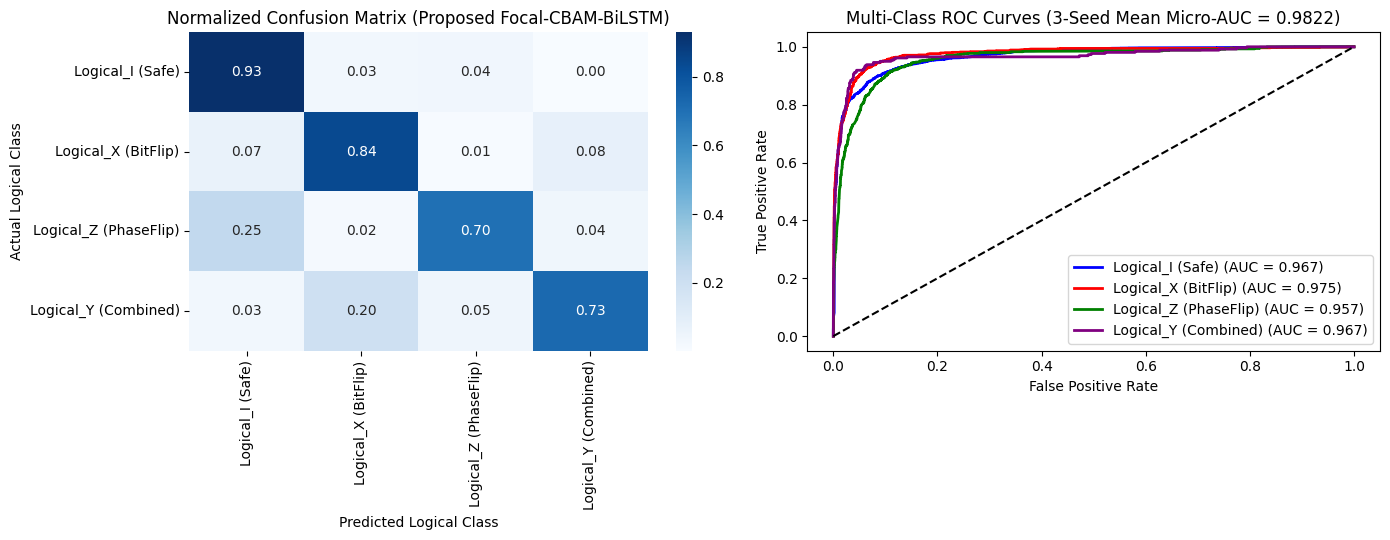

In [5]:
# ==============================================================================
# 4. FINAL 3-SEED SUMMARY TABLE (MEAN ± STD) & PLOTS
# ==============================================================================
print("\n" + "="*80)
print("FINAL 3-SEED BENCHMARK SUMMARY (MEAN ± STD) — ROTATED d=3 NON-PAULI SURFACE CODE")
print("="*80)
for name in ["MWPM", "MLP_CE", "Proposed"]:
    ler_m, ler_s = np.mean(results[name]["ler"]), np.std(results[name]["ler"])
    f1_m, f1_s = np.mean(results[name]["macro_f1"]), np.std(results[name]["macro_f1"])
    yr_m, yr_s = np.mean(results[name]["y_recall"]), np.std(results[name]["y_recall"])
    auc_str = f"{np.mean(results[name]['micro_auc']):.4f} ± {np.std(results[name]['micro_auc']):.4f}" if "micro_auc" in results[name] else "N/A (Hard Decision)"
    print(f"{name:10s} | LER (Lower Better): {ler_m:5.2f} ± {ler_s:.2f}% | Macro-F1: {f1_m:5.2f} ± {f1_s:.2f}% | Y-Recall: {yr_m:5.2f} ± {yr_s:.2f}% | Micro-AUC: {auc_str}")

y_te, pred_prop, y_te_oh, prob_prop = last_cm_data
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
cm_norm = confusion_matrix(y_te, pred_prop, normalize='true')
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title("Normalized Confusion Matrix (Proposed Focal-CBAM-BiLSTM)")
axes[0].set_xlabel("Predicted Logical Class")
axes[0].set_ylabel("Actual Logical Class")

for i, color in enumerate(['blue', 'red', 'green', 'purple']):
    fpr, tpr, _ = roc_curve(y_te_oh[:, i], prob_prop[:, i])
    roc_auc = roc_auc_score(y_te_oh[:, i], prob_prop[:, i])
    axes[1].plot(fpr, tpr, color=color, lw=2, label=f"{class_names[i]} (AUC = {roc_auc:.3f})")
axes[1].plot([0, 1], [0, 1], 'k--', lw=1.5)
axes[1].set_title(f"Multi-Class ROC Curves (3-Seed Mean Micro-AUC = {np.mean(results['Proposed']['micro_auc']):.4f})")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.savefig("Upgraded_SurfaceCode_MWPM_vs_Proposed.png", dpi=300)
plt.show()